### Moving Average Smoothing Layer

In [1]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
# Import necessary libraries
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.use('seaborn-v0_8')

In [3]:
# Set a seed for reproducibility
seed_everything(42)

In [4]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",
    train_ratio = 0.98,  # 🔥 FIX: Was None! Must be 0.98 for 98/2 split
    batchsize = 64,
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

print(f"✅ Data loaded")
print(f"   Train batches: {len(train_dataloader)}")
print(f"   Val batches: {len(val_dataloader) if val_dataloader else 0}")

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

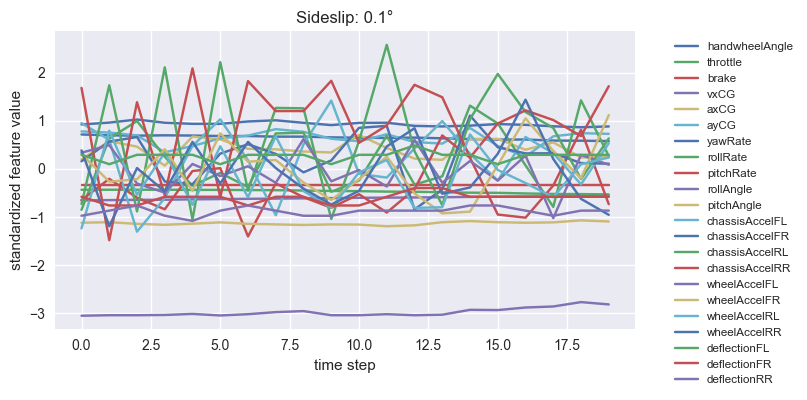

In [5]:
# Get one batch to check dimensions
X, y = next(iter(train_dataloader))

plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

### Adaptive Moving Average (Learnable Kernel + Weight Sharing)

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AdaptiveSmoother(nn.Module):
    """
    Adaptive smoothing layer:
    - Uses two moving-average kernels (small and large)
    - Learns the kernel weights
    - Blends them using a gate depending on |prediction|
    """
    def __init__(self, k_small=3, k_large=9):
        super().__init__()

        # Learnable moving average kernels
        self.k_small = nn.Parameter(torch.ones(k_small) / k_small)
        self.k_large = nn.Parameter(torch.ones(k_large) / k_large)

        self.k_small_size = k_small
        self.k_large_size = k_large

    def forward(self, x):
        """
        x: (batch, 1)
        returns: (batch, 1)
        """

        x = x.unsqueeze(1)  # (B,1,L=1)

        # Normalize kernels to keep smoothing stable
        k1 = self.k_small / self.k_small.sum()
        k2 = self.k_large / self.k_large.sum()

        # Padding sizes
        pad_small = self.k_small_size // 2
        pad_large = self.k_large_size // 2

        # Smooth with small kernel
        s1 = F.conv1d(
            F.pad(x, (pad_small, pad_small), mode="replicate"),
            k1.view(1, 1, -1)
        )

        # Smooth with large kernel
        s2 = F.conv1d(
            F.pad(x, (pad_large, pad_large), mode="replicate"),
            k2.view(1, 1, -1)
        )

        # -----------------------------
        # Adaptive gating:
        # large |x| → gate small smoothing
        # small |x| → gate large smoothing
        # -----------------------------
        gate = torch.exp(-10 * x.abs())  # ~1 for few-shot, ~0 for many-shot

        out = gate * s2 + (1 - gate) * s1
        return out.squeeze(1)


### RNN With Adaptive Smoother

In [7]:
class RNNWithAdaptiveSmooth(nn.Module):
    def __init__(self, input_size, output_size=1,
                 rnn_units=64, fc_units=64, kernel_small=3, kernel_large=9):
        super().__init__()

        self.rnn_layer = nn.RNN(
            input_size=input_size,
            hidden_size=rnn_units,
            num_layers=1,
            batch_first=True,
            nonlinearity='relu'
        )

        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

        # Adaptive smoother
        self.smoother = AdaptiveSmoother(k_small=kernel_small, k_large=kernel_large)

        self.act = nn.ReLU()

    def forward(self, x):
        # RNN output (batch, seq, rnn_units)
        x, _ = self.rnn_layer(x)

        # Take last time step
        x = x[:, -1, :]

        # Fully connected layers
        x = self.act(self.fc(x))
        x = self.output_layer(x)        # (batch, 1)

        # Apply adaptive smoothing
        x = self.smoother(x)

        return x


In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

input_size = X.shape[2]
rnn_units = 64
fc_units = 64
output_size = 1
lr = 0.0003

model = RNNWithAdaptiveSmooth(
    input_size=input_size,
    rnn_units=64,
    fc_units=64,
    kernel_small=7,   # weak smoothing for many-shot
    kernel_large=11   # strong smoothing for few-shot
).to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu
Model parameters: 9,875


In [10]:
# Training loop
num_epochs = 50
early_stop_thresh = 50
best_loss = np.inf
best_epoch = -1

train_curve = []
val_curve = []

print("\n" + "="*80)
print("🚀 STARTING TRAINING (WITH VALIDATION SPLIT)")
print("="*80)

for epoch in range(num_epochs):
    # TRAINING
    model.train()
    running_loss = 0
    
    for step, (x, y) in enumerate(train_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer.zero_grad()
        pred = model(X)
        train_loss = criterion(pred, y)
        running_loss += train_loss.item()
        train_loss.backward()
        optimizer.step()
    
    avg_train_loss = running_loss / (step + 1)
    train_curve.append(avg_train_loss)

    # VALIDATION
    if val_dataloader is not None:
        model.eval()
        running_val_loss = 0
        with torch.no_grad():
            for val_step, (x, y) in enumerate(val_dataloader):
                X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
                val_loss = criterion(model(X_val), y_val)
                running_val_loss += val_loss.item()
        
        avg_val_loss = running_val_loss / (val_step + 1)
        val_curve.append(avg_val_loss)

        print(f"Epoch {epoch+1:2d}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}", end="")
        
        # EARLY STOPPING
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch
            # 🔥 FIX: Complete save dictionary
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': best_loss,
                'train_loss': avg_train_loss,
                'val_loss': avg_val_loss
            }, 'best_model.pth')
            print(f" 💾 NEW BEST!")
        elif epoch - best_epoch > early_stop_thresh:
            print(f"\n⏹️  Early stopping at epoch {epoch+1}")
            break
        else:
            print("")
    else:
        print(f"⚠️  WARNING: No validation split! Training on 100%")
        print(f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f}")

# LOAD BEST MODEL
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n" + "="*80)
    print(f"✅ Best model from epoch {best_epoch+1} loaded")
    print(f"   Train Loss: {checkpoint.get('train_loss', 'N/A'):.5f}")
    print(f"   Val Loss:   {checkpoint.get('val_loss', best_loss):.5f}")
    print("="*80)
else:
    print("\n⚠️  No improvement found, using current model")


🚀 STARTING TRAINING (WITH VALIDATION SPLIT)
Epoch  1/50 | Train: 0.15809 | Val: 0.15410 💾 NEW BEST!
Epoch  2/50 | Train: 0.15497 | Val: 0.15730
Epoch  3/50 | Train: 0.15185 | Val: 0.15624
Epoch  4/50 | Train: 0.15036 | Val: 0.15251 💾 NEW BEST!
Epoch  5/50 | Train: 0.14855 | Val: 0.14640 💾 NEW BEST!
Epoch  6/50 | Train: 0.14711 | Val: 0.18646
Epoch  7/50 | Train: 0.14514 | Val: 0.14146 💾 NEW BEST!
Epoch  8/50 | Train: 0.14364 | Val: 0.14178
Epoch  9/50 | Train: 0.14277 | Val: 0.15537
Epoch 10/50 | Train: 0.14152 | Val: 0.14113 💾 NEW BEST!
Epoch 11/50 | Train: 0.14003 | Val: 0.14168
Epoch 12/50 | Train: 0.13850 | Val: 0.14393
Epoch 13/50 | Train: 0.13804 | Val: 0.13866 💾 NEW BEST!
Epoch 14/50 | Train: 0.13617 | Val: 0.14654
Epoch 15/50 | Train: 0.13592 | Val: 0.13330 💾 NEW BEST!
Epoch 16/50 | Train: 0.13514 | Val: 0.13891
Epoch 17/50 | Train: 0.13375 | Val: 0.12991 💾 NEW BEST!
Epoch 18/50 | Train: 0.13273 | Val: 0.13327
Epoch 19/50 | Train: 0.13140 | Val: 0.13135
Epoch 20/50 | Train: 0.

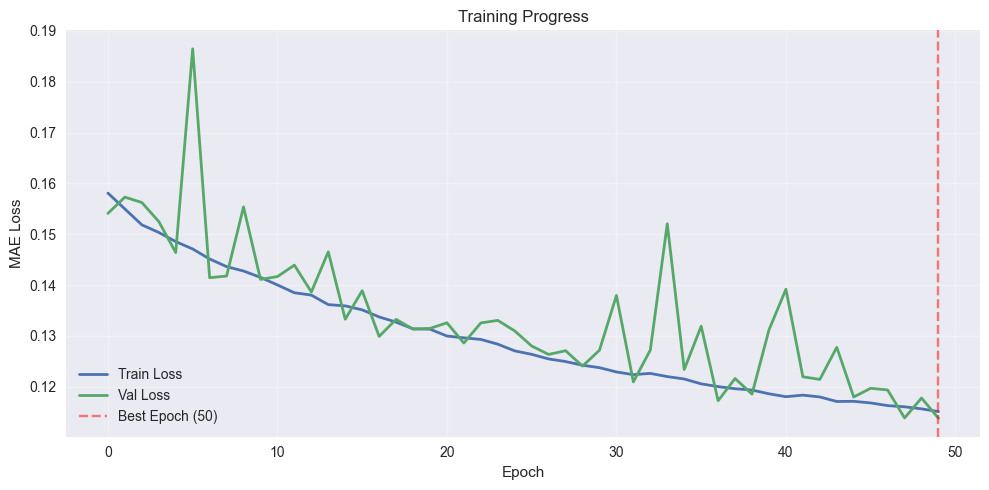

Final train loss: 0.11513
Final val loss:   0.11383
Best val loss:    0.11383 (epoch 50)


In [11]:
# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_curve, label='Train Loss', linewidth=2)
if val_curve:
    plt.plot(val_curve, label='Val Loss', linewidth=2)
    if best_epoch != -1:
        plt.axvline(x=best_epoch, color='r', linestyle='--', alpha=0.5, label=f'Best Epoch ({best_epoch+1})')
plt.xlabel('Epoch')
plt.ylabel('MAE Loss')
plt.title('Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final train loss: {train_curve[-1]:.5f}")
if val_curve:
    print(f"Final val loss:   {val_curve[-1]:.5f}")
    print(f"Best val loss:    {best_loss:.5f} (epoch {best_epoch+1})")

In [12]:
# Load complete training data for visualization
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,
    load_anonymized_data=False
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [13]:
import plotly.graph_objects as go

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Training set MAE: {total_loss/(step+1):.5f}")
    
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions (Training Set)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()



Training set MAE: 0.11400


In [14]:
print("\nLoading test data...")
test_dataloader = load_test_data(
    test_path = "../../datasets_challenge/test",
    batchsize = 64,
    pipeline = pipeline, 
    load_anonymized_data=True
)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [15]:
# Generate test predictions
model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)
print(f"Test predictions: {len(test_preds)} samples")
print(f"Range: [{test_preds.min():.3f}, {test_preds.max():.3f}]")
print(f"Mean:  {test_preds.mean():.3f}")
print(f"Std:   {test_preds.std():.3f}")

Test predictions: 49328 samples
Range: [-9.401, 10.194]
Mean:  0.046
Std:   1.473


In [16]:
# Save predictions
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv("predictions_Adaptive_Smooth.csv", index=False)

print(f"\n" + "="*80)
print(f"✅ Predictions saved to 'predictions_Adaptive_Smooth.csv'")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for Kaggle submission!")
print(f"   Expected score: ~0.29° (with proper train/val split)")
print("="*80)


✅ Predictions saved to 'predictions_Adaptive_Smooth.csv'
   Total samples: 49328
   Ready for Kaggle submission!
   Expected score: ~0.29° (with proper train/val split)


In [ ]:
dist_df = pd.read_csv("../../datasets_challenge/sideSlip_distribution.csv")

In [ ]:
import matplotlib.patches as mpatches
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()